<a href="https://colab.research.google.com/github/aarushipandey06/coupled-oscillations/blob/main/Coupled_Oscillation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# **Theoretical Background**

## 1. Physical Model

The system consists of two identical masses, each of mass $m$, connected by three identical springs, each having spring constant $k$. The outer ends of the two outer springs are fixed to rigid walls, while the middle spring connects the two masses.

The masses are displaced horizontally from their equilibrium positions. Let $x_1(t)$ and $x_2(t)$ represent the displacements of the first and second masses, respectively, at time $t$.

The system is assumed to be ideal, with no damping or external forces. The motion of each mass depends on the restoring forces exerted by the springs and the displacement of the other mass.

## 2. Equations of Motion

According to Hooke's law, the restoring force exerted by a spring is proportional to its extension and acts in the opposite direction.

### *Mass 1*

The left spring exerts a force $-kx_1$, while the middle spring exerts a force $k(x_2-x_1)$.

Using Newton's second law, $F=ma$:

$$
m\ddot{x}_1=-kx_1+k(x_2-x_1)
$$

Simplifying:

$$
m\ddot{x}_1=-2kx_1+kx_2
$$

Therefore,

$$
\boxed{\ddot{x}_1=\frac{-2kx_1+kx_2}{m}}
$$

### *Mass 2*

The right spring exerts a force $-kx_2$, while the middle spring exerts a force $-k(x_2-x_1)$ on the second mass.

Using Newton's second law:

$$
m\ddot{x}_2=-kx_2-k(x_2-x_1)
$$

Simplifying:

$$
m\ddot{x}_2=kx_1-2kx_2
$$

Therefore,

$$
\boxed{\ddot{x}_2=\frac{kx_1-2kx_2}{m}}
$$

These coupled differential equations describe the motion of both masses. Since the acceleration of each mass depends on the displacement of both masses, their motions are coupled.

## 3. Normal Modes and Theoretical Frequencies

A normal mode is a pattern of oscillation in which all masses oscillate at the same angular frequency, maintaining a fixed relationship between their amplitudes.

To determine the normal-mode frequencies, assume solutions of the form:

$$
x_1=A_1e^{i\omega t}, \qquad x_2=A_2e^{i\omega t}
$$

where $A_1$ and $A_2$ are the amplitudes, $\omega$ is the angular frequency, and $i=\sqrt{-1}$.

Differentiating twice with respect to time gives:

$$
\ddot{x}_1=-\omega^2x_1, \qquad
\ddot{x}_2=-\omega^2x_2
$$

Substituting into the equations of motion:

$$
(2k-m\omega^2)A_1-kA_2=0
$$

$$
-kA_1+(2k-m\omega^2)A_2=0
$$

For a non-zero solution for the amplitudes, the determinant of the coefficient matrix must vanish:

$$
\begin{vmatrix}
2k-m\omega^2 & -k \\
-k & 2k-m\omega^2
\end{vmatrix}=0
$$

Expanding the determinant:

$$
(2k-m\omega^2)^2-k^2=0
$$

Factoring:

$$
(k-m\omega^2)(3k-m\omega^2)=0
$$

Hence, the two angular frequencies are:

$$
\boxed{\omega_1=\sqrt{\frac{k}{m}}}
$$

$$
\boxed{\omega_2=\sqrt{\frac{3k}{m}}}
$$

Angular frequency and ordinary frequency are related by $\omega=2\pi f$. Therefore, the theoretical normal-mode frequencies are:

$$
\boxed{f_1=\frac{1}{2\pi}\sqrt{\frac{k}{m}}}
$$

$$
\boxed{f_2=\frac{1}{2\pi}\sqrt{\frac{3k}{m}}}
$$

### Normal-Mode Shapes

For the first mode, $\omega_1^2=k/m$. Substituting into the amplitude equations gives $A_1=A_2$.

Both masses move in the same direction with equal amplitudes. This is called the **in-phase mode**.

For the second mode, $\omega_2^2=3k/m$. Substituting into the amplitude equations gives $A_1=-A_2$.

The masses move in opposite directions with equal amplitudes. This is called the **out-of-phase mode**.

For the simulation parameters $m=1.0\,\text{kg}$ and $k=1.0\,\text{N/m}$, the theoretical frequencies are:

$$
f_1=\frac{1}{2\pi}\approx 0.15915\,\text{Hz}
$$

$$
f_2=\frac{\sqrt{3}}{2\pi}\approx 0.27566\,\text{Hz}
$$

These values will be compared with the frequencies extracted from the simulated motion using Fourier analysis.


# 1. Euler Simulation

## Numerical Integration and Error Analysis

The equations of motion are second-order differential equations. To solve them numerically, they can be rewritten as first-order equations involving position and velocity:

$$
\boxed{\frac{dx_1}{dt}=v_1} \quad
\boxed{\frac{dx_2}{dt}=v_2} \quad
\boxed{\frac{dv_1}{dt}=\frac{-2kx_1+kx_2}{m}} \quad
\boxed{\frac{dv_2}{dt}=\frac{kx_1-2kx_2}{m}}
$$

The Euler method advances the solution in small time steps using the current velocities and accelerations:

$$
x_{1,n+1}=x_{1,n}+v_{1,n}\Delta t
$$

$$
x_{2,n+1}=x_{2,n}+v_{2,n}\Delta t
$$

$$
v_{1,n+1}=v_{1,n}+a_{1,n}\Delta t
$$

$$
v_{2,n+1}=v_{2,n}+a_{2,n}\Delta t
$$

Here, $\Delta t$ is the time step, and the subscript $n$ denotes the current time step.

The accuracy of the numerical solution depends on the integration method and the chosen time step. A smaller time step generally reduces the local truncation error, although it also increases the computational cost. Comparing results at different time steps helps evaluate convergence, while comparing Euler with the fourth-order Runge-Kutta (RK4) method helps assess the effect of the integration scheme.

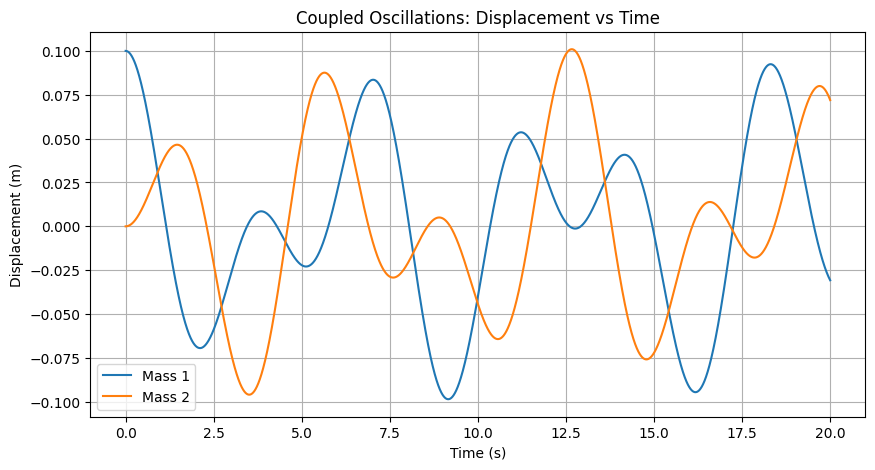

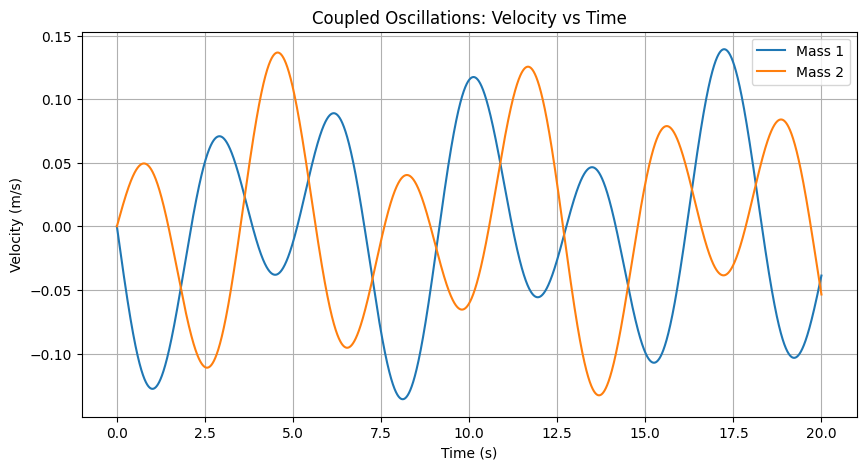

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Fixed conditions
m = 1.0
k = 1.0
dt = 0.001
total_time = 20.0

def euler_simulation(dt, total_time):
    # Initial conditions (reset for every simulation)
    x1, x2 = 0.10, 0.0
    v1, v2 = 0.0, 0.0

    # Lists to store results
    time_values = []
    x1_values, x2_values = [], []
    v1_values, v2_values = [], []

    steps = int(total_time / dt)

    for i in range(steps + 1):
        t = i * dt

        # Storing current state
        time_values.append(t)
        x1_values.append(x1)
        x2_values.append(x2)
        v1_values.append(v1)
        v2_values.append(v2)

        if i == steps:
            break

        # Calculating accelerations
        a1 = (-2 * k * x1 + k * x2) / m
        a2 = (k * x1 - 2 * k * x2) / m

        # Explicit Euler updates
        x1_new = x1 + v1 * dt
        x2_new = x2 + v2 * dt

        v1_new = v1 + a1 * dt
        v2_new = v2 + a2 * dt

        x1, x2 = x1_new, x2_new
        v1, v2 = v1_new, v2_new

    return time_values, x1_values, x2_values, v1_values, v2_values

time_values, x1_values, x2_values, v1_values, v2_values = euler_simulation(dt, total_time)

# Plotting displacement vs time
plt.figure(figsize=(10, 5))
plt.plot(time_values, x1_values, label="Mass 1")
plt.plot(time_values, x2_values, label="Mass 2")
plt.xlabel("Time (s)")
plt.ylabel("Displacement (m)")
plt.title("Coupled Oscillations: Displacement vs Time")
plt.legend()
plt.grid(True)
plt.show()

# Plotting velocity vs time
plt.figure(figsize=(10, 5))
plt.plot(time_values, v1_values, label="Mass 1")
plt.plot(time_values, v2_values, label="Mass 2")
plt.xlabel("Time (s)")
plt.ylabel("Velocity (m/s)")
plt.title("Coupled Oscillations: Velocity vs Time")
plt.legend()
plt.grid(True)
plt.show()

# Graph Interpretation
1. Displacement vs Time

Both masses exhibit oscillatory motion, with their displacements changing over time due to the restoring forces of the springs. Since the initial displacement of the first mass excites both normal modes, the resulting motion is a superposition of oscillations at the two normal-mode frequencies. The motion is therefore more complex than a single sinusoidal oscillation.

2. Velocity vs Time

The velocities of both masses vary periodically as the system oscillates. Velocity is zero at the initial instant because both masses start from rest. As the masses move, elastic potential energy is converted into kinetic energy and vice versa. The coupled equations of motion determine how the velocities of the two masses evolve together.

# 2. Energy Calculation


## Total Mechanical Energy

The total mechanical energy of the system is the sum of its kinetic and potential energies.

### Kinetic Energy

Both masses contribute to the total kinetic energy:

$$
KE=\frac{1}{2}m\dot{x}_1^2+\frac{1}{2}m\dot{x}_2^2
$$

Therefore,

$$
\boxed{KE=\frac{1}{2}m(\dot{x}_1^2+\dot{x}_2^2)}
$$

### Potential Energy

The extensions of the left, middle, and right springs are $x_1$, $x_2-x_1$, and $x_2$, respectively. The potential energy stored in a spring with extension $x$ is $\frac{1}{2}kx^2$.

Adding the contributions from all three springs gives:

$$
PE=\frac{1}{2}kx_1^2+
\frac{1}{2}k(x_2-x_1)^2+
\frac{1}{2}kx_2^2
$$

Therefore,

$$
\boxed{PE=\frac{1}{2}k[x_1^2+(x_2-x_1)^2+x_2^2]}
$$

The total mechanical energy is:

$$
\boxed{E=KE+PE}
$$

For an ideal system without damping or external forces, total mechanical energy should remain constant. However, numerical integration methods introduce approximation errors that can cause the calculated energy to drift over time.

Monitoring the change in total energy provides a way to assess the accuracy and stability of the numerical simulation.


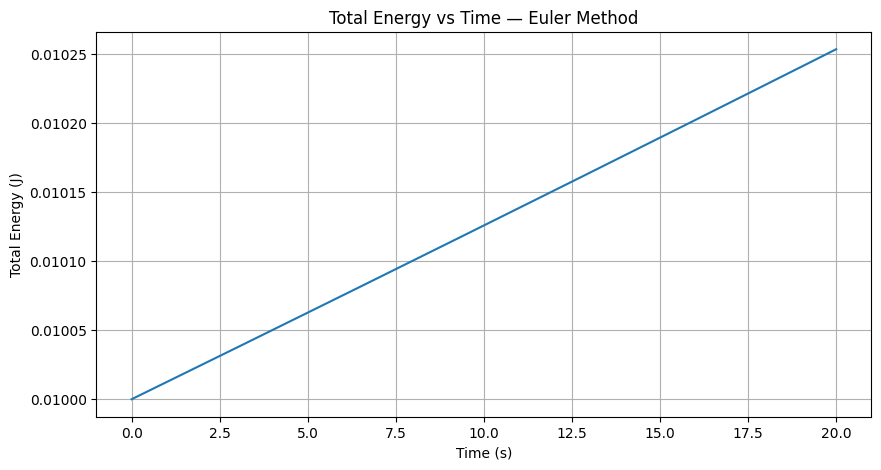

In [ ]:

# Calculating total energy
def total_energy(time_values, x1_values,
 x2_values, v1_values, v2_values):

  energy_values = []
  for t, x1, x2, v1, v2 in zip(
        time_values, x1_values, x2_values, v1_values, v2_values):
        KE = 0.5 * m * (v1**2 + v2**2)

        PE = 0.5 * k * (x1**2 + (x2 - x1)**2 + x2**2)

        energy_values.append(KE + PE)

  return energy_values

# Calculating total energy from existing simulation
energy_values = total_energy(
    time_values, x1_values, x2_values, v1_values, v2_values)

# Plotting total energy over time
plt.figure(figsize=(10, 5))
plt.plot(time_values, energy_values)
plt.xlabel("Time (s)")
plt.ylabel("Total Energy (J)")
plt.title("Total Energy vs Time — Euler Method")
plt.grid(True)
plt.show()

### Graph Interpretation: Total Energy vs Time - Euler Method

For an ideal undamped system, the total mechanical energy should remain constant. However, the Euler method introduces numerical errors at each time step, causing the calculated energy to drift over time. In this simulation, the total energy rises from approximately 0.01000 J to 0.010254 J over 20 seconds. This demonstrates that the numerical solution does not preserve the system's energy exactly and motivates investigating the effect of the time step on accuracy.

# 2.1. Convergence analysis for energy

Time step | Final energy (J) | Final energy error (%)
------------------------------------------------------
  0.0100 |       0.01671814 |            67.181377
  0.0050 |       0.01288675 |            28.867510
  0.0010 |       0.01051428 |             5.142767
  0.0005 |       0.01025353 |             2.535343


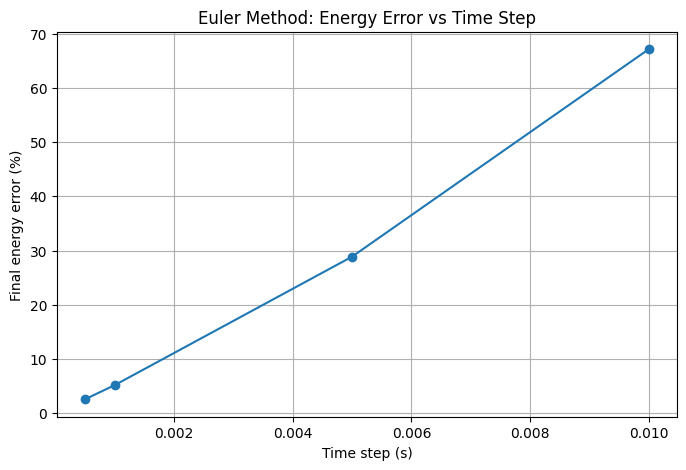

In [ ]:
dt_values = [0.01, 0.005, 0.001, 0.0005]
results = []

# Initial energy
E_initial = total_energy([0], [0.10], [0.0], [0.0], [0.0])[0]

for dt_test in dt_values:

    time_values, x1_values, x2_values, v1_values, v2_values = (
    euler_simulation(dt_test, total_time) )

    # Calculating energy at every timestep
    energy_test = total_energy(
        time_values,
        x1_values,
        x2_values,
        v1_values,
        v2_values )

    # Extracting the final energy
    E_final = energy_test[-1]

    # Calculating percentage energy error
    error = abs(E_final - E_initial) / E_initial * 100

    results.append((dt_test, E_final, error))

# Displaying results
print("Time step | Final energy (J) | Final energy error (%)")
print("------------------------------------------------------")

for dt_test, E_final, error in results:
    print(f"{dt_test:8.4f} | {E_final:16.8f} | {error:20.6f}")

# Plotting energy error vs time step
plt.figure(figsize=(8, 5))
plt.plot(
    [r[0] for r in results],
    [r[2] for r in results],
    "o-")

plt.xlabel("Time step (s)")
plt.ylabel("Final energy error (%)")
plt.title("Euler Method: Energy Error vs Time Step")
plt.grid(True)
plt.show()

### Graph Interpretation

The final energy error decreases as the time step is reduced. For example, reducing the time step from $0.001$ s to $0.0005$ s decreases the final energy error from approximately $5.14%$ to $2.54%$. This trend indicates that smaller time steps improve the accuracy of the Euler simulation over the fixed 20-second interval. The results are consistent with the first-order global accuracy expected from the explicit Euler method.

# 3. Comparing Euler and RK4

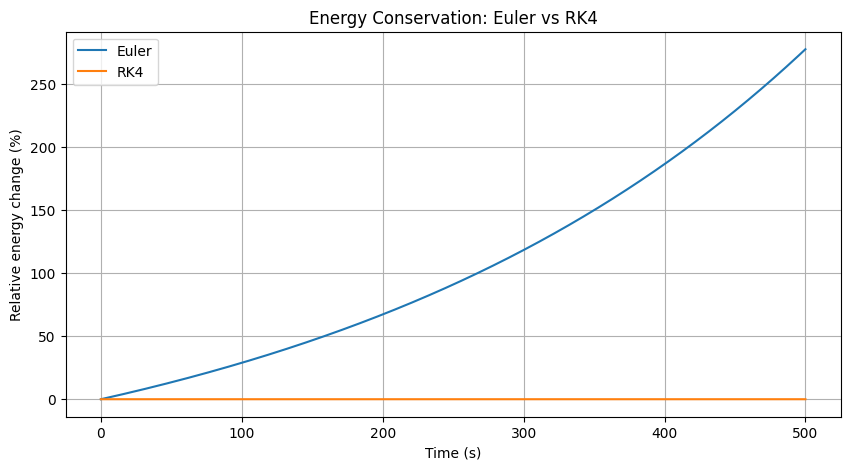

Maximum absolute relative energy change:
Euler: 277.343945%
RK4:   0.000000%
RK4(scientific notation): 1.5022705302e-11%


In [ ]:
# Initial conditions
m = 1.0
k = 1.0
dt = 0.001
total_time = 500.0

# Calculating acceleration
def derivatives(state):
    x1, x2, v1, v2 = state

    a1 = (-2 * k * x1 + k * x2) / m
    a2 = (k * x1 - 2 * k * x2) / m

    return np.array([v1, v2, a1, a2])

# Calculating energy
def energy(state):
    x1, x2, v1, v2 = state

    KE = 0.5 * m * (v1**2 + v2**2)
    PE = 0.5 * k * (x1**2 + (x2 - x1)**2 + x2**2)

    return KE + PE

# Defining a method for RK4 and Euler both
def simulate(method):
    state = np.array([0.10, 0.0, 0.0, 0.0])
    times = [0.0]
    states = [state.copy()]
    energies = [energy(state)]

    steps = int(total_time / dt)

    for i in range(steps):
        if method == "Euler":
            state = state + dt * derivatives(state)

        elif method == "RK4":
            a = derivatives(state)
            b = derivatives(state + 0.5 * dt * a)
            c = derivatives(state + 0.5 * dt * b)
            d = derivatives(state + dt * c)

            state = state + (dt / 6) * (a + 2*b + 2*c + d)

        times.append((i + 1) * dt)
        states.append(state.copy())
        energies.append(energy(state))

    return np.array(times), np.array(states), np.array(energies)

t_euler, s_euler, E_euler = simulate("Euler")
t_rk4, s_rk4, E_rk4 = simulate("RK4")

E0 = E_euler[0]

# Plotting relative energy change vs time
plt.figure(figsize=(10, 5))
plt.plot(t_euler, (E_euler - E0) / E0 * 100, label="Euler")
plt.plot(t_rk4, (E_rk4 - E0) / E0 * 100, label="RK4")
plt.xlabel("Time (s)")
plt.ylabel("Relative energy change (%)")
plt.title("Energy Conservation: Euler vs RK4")
plt.legend()
plt.grid(True)
plt.show()

# Displaying maximum energy changes
print("Maximum absolute relative energy change:")
print(f"Euler: {np.max(np.abs(E_euler - E0)) / E0 * 100:.6f}%")
print(f"RK4:   {np.max(np.abs(E_rk4 - E0)) / E0 * 100:.6f}%")
rk4_error = np.max(np.abs(E_rk4 - E0)) / E0 * 100
print(f"RK4(scientific notation): {rk4_error:.10e}%")

### Graph Interpretation

The energy comparison shows a substantial difference between the two integration methods over the 500-second simulation. The Euler method exhibits significant energy drift, whereas RK4 maintains the calculated energy much closer to its initial value. The maximum absolute relative energy changes are approximately $277.34\%$ for Euler and $1.50\times10^{-11}\%$ for RK4. Under the chosen conditions, RK4 therefore provides much better energy stability over the simulated interval, although it does not conserve energy exactly in general.

# 4. Finding normal mode frequencies using FFT

## Frequency Analysis Using the Fast Fourier Transform

The simulated displacement signals contain oscillations associated with the system's normal modes. The Fast Fourier Transform (FFT) converts a time-domain signal into its frequency-domain representation, allowing the dominant frequencies to be identified.

The frequencies corresponding to prominent peaks in the Fourier spectrum are taken as estimates of the simulated normal-mode frequencies.

These numerical estimates are compared with the theoretical values:

$$
f_1\approx 0.15915\,\text{Hz}, \qquad
f_2\approx 0.27566\,\text{Hz}
$$

Agreement between the theoretical and simulated frequencies supports the correctness of the equations of motion and the numerical implementation. Any discrepancy may arise from numerical errors, finite simulation duration, and the frequency resolution of the FFT.

Theoretical frequencies: [0.15915494 0.27566445]
Mass 1 frequencies: [0.15999968 0.27599945]
Mass 2 frequencies: [0.15999968 0.27599945]


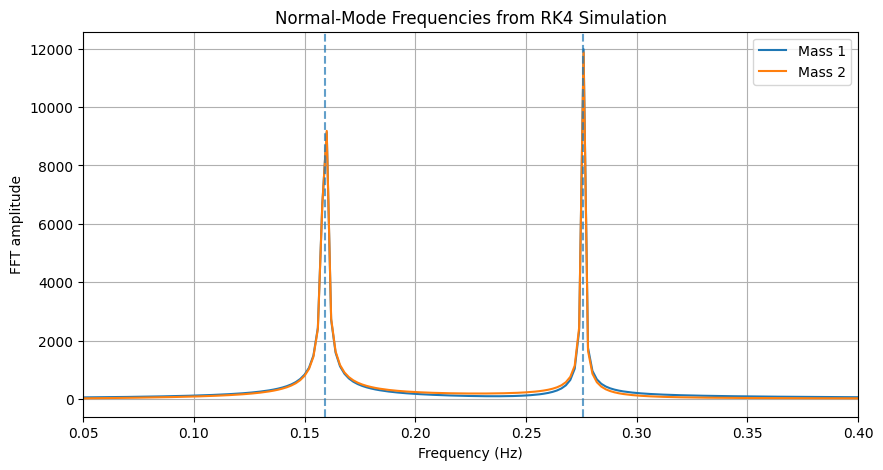

In [ ]:
from scipy.signal import find_peaks

# Extracting RK4 displacement data
x1_rk4 = s_rk4[:, 0]
x2_rk4 = s_rk4[:, 1]

dt_actual = t_rk4[1] - t_rk4[0]

# Calculating FFT
frequencies = np.fft.rfftfreq(len(t_rk4), d=dt_actual)

fft1 = np.abs(np.fft.rfft(x1_rk4 - np.mean(x1_rk4)))
fft2 = np.abs(np.fft.rfft(x2_rk4 - np.mean(x2_rk4)))

# Ignoring zero frequency and search for peaks
mask = (frequencies > 0.05) & (frequencies < 0.4)
freq_range = frequencies[mask]
spectrum1 = fft1[mask]
spectrum2 = fft2[mask]

peaks1, _ = find_peaks(spectrum1)
peaks2, _ = find_peaks(spectrum2)

# Displaying the two strongest peaks
strongest1 = peaks1[np.argsort(spectrum1[peaks1])[-2:]]
strongest2 = peaks2[np.argsort(spectrum2[peaks2])[-2:]]

found1 = np.sort(freq_range[strongest1])
found2 = np.sort(freq_range[strongest2])

print("Theoretical frequencies:", np.sqrt([k/m, 3*k/m]) / (2*np.pi))
print("Mass 1 frequencies:", found1)
print("Mass 2 frequencies:", found2)

# Plotting the spectra
plt.figure(figsize=(10, 5))
plt.plot(frequencies, fft1, label="Mass 1")
plt.plot(frequencies, fft2, label="Mass 2")

for f in np.sqrt([k/m, 3*k/m]) / (2*np.pi):
    plt.axvline(f, linestyle="--", alpha=0.7)

plt.xlim(0.05, 0.4)
plt.xlabel("Frequency (Hz)")
plt.ylabel("FFT amplitude")
plt.title("Normal-Mode Frequencies from RK4 Simulation")
plt.legend()
plt.grid(True)
plt.show()

### Graph Interpretation

The Fourier spectra contain prominent peaks near the two theoretical normal-mode frequencies. These peaks indicate the dominant oscillation frequencies present in the simulated displacement signals. The vertical dashed lines mark the theoretical predictions, allowing a visual comparison with the numerical estimates. The small discrepancies between the detected and theoretical frequencies are consistent with the finite frequency resolution of the FFT and other numerical effects.

# 4.1. Error in frequency

In [ ]:
# Theoretical normal-mode frequencies
f_theory_1 = (1 / (2 * np.pi)) * np.sqrt(k / m)
f_theory_2 = (1 / (2 * np.pi)) * np.sqrt(3 * k / m)

# Averaging the frequencies detected from both masses
f_fft_1 = np.mean([found1[0], found2[0]])
f_fft_2 = np.mean([found1[1], found2[1]])

# Calculating percentage errors
error_1 = abs(f_fft_1 - f_theory_1) / f_theory_1 * 100
error_2 = abs(f_fft_2 - f_theory_2) / f_theory_2 * 100

# Displaying the comparison
print("Frequency Comparison")
print("-" * 65)
print(f"{'Mode':<10}{'Theoretical (Hz)':<22}"
      f"{'FFT (Hz)':<16}{'Error (%)'}")

print("-" * 65)
print(f"{'Mode 1':<10}{f_theory_1:<22.8f}"
      f"{f_fft_1:<16.8f}{error_1:.4f}")

print(f"{'Mode 2':<10}{f_theory_2:<22.8f}"
      f"{f_fft_2:<16.8f}{error_2:.4f}")

Frequency Comparison
-----------------------------------------------------------------
Mode      Theoretical (Hz)      FFT (Hz)        Error (%)
-----------------------------------------------------------------
Mode 1    0.15915494            0.15999968      0.5308
Mode 2    0.27566445            0.27599945      0.1215


### Result

The FFT estimates are approximately $0.16000$ Hz and $0.27600$ Hz, compared with theoretical values of $0.15915$ Hz and $0.27566$ Hz. The corresponding percentage errors are approximately $0.5308\%$ and $0.1215\%$ respectively. Both estimates are close to the theoretical predictions. The remaining discrepancies should be interpreted in light of the FFT's finite frequency resolution rather than attributed solely to integration error.



## Conclusion

This project investigated the coupled oscillations of two identical masses connected by three identical springs using numerical integration. The equations of motion were implemented using the Euler method and the fourth-order Runge–Kutta (RK4) method.

The displacement plots were used to examine the oscillatory behaviour of the system. The conservation of total mechanical energy was investigated to assess numerical accuracy, and the results obtained using different time steps were compared to study the effect of time-step size on the simulation.

The numerical frequencies extracted using the Fast Fourier Transform (FFT) were compared with the theoretical normal-mode frequencies of approximately $0.15915\,\text{Hz}$ and $0.27566\,\text{Hz}$. The agreement between these values was used to assess whether the simulated motion was consistent with the theoretical model.

Overall, this project demonstrates how numerical methods can be used to investigate coupled mechanical systems and how energy analysis, time-step studies, and frequency-domain analysis can help evaluate the reliability of a numerical simulation.
